# Bài 3: ResNet-18 từ đầu trên VinaFood21

So sánh ResNet-18 không augmentation và có augmentation.

In [ ]:
EXERCISE = 3

from pathlib import Path
import os
import sys
import json

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

CODE_DIR = Path(f"*path chứa source code*")
DATA_ROOT = Path("*path chứa dữ liệu VinaFood21*")
OUTPUT_DIR = Path(f"*path chứa output*")

if not (CODE_DIR / "train.py").is_file():
    raise FileNotFoundError(f"Không tìm thấy train.py tại {CODE_DIR}")
if not (DATA_ROOT / "train").is_dir() or not (DATA_ROOT / "test").is_dir():
    raise FileNotFoundError(
        f"DATA_ROOT phải chứa trực tiếp train/ và test/: {DATA_ROOT}"
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))
os.chdir(CODE_DIR)

print("Code:", CODE_DIR)
print("Data:", DATA_ROOT)
print("Output:", OUTPUT_DIR)

Code: /kaggle/input/datasets/vantien113/code-lab2/3/3
Data: /kaggle/input/datasets/maivthysao/lab2-bai3/VinaFood21/VinaFood21
Output: /kaggle/working/lab2_bai3_outputs


## 1. Kiểm tra môi trường và cấu hình

In [ ]:
RUN_TRAIN = True
RUN_EVALUATION = True

SEED = 42
BATCH_SIZE = 32
NUM_WORKERS = 2
EPOCHS = 20
IMAGE_SIZE = 96

import torch
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("Epochs:", EPOCHS, "| Batch size:", BATCH_SIZE, "| Image size:", IMAGE_SIZE)
if DEVICE.type != "cuda":
    print("Chưa bật GPU")

PyTorch: 2.11.0+cu128
Device: cuda
Epochs: 20 | Batch size: 32 | Image size: 96


In [ ]:
def run_module_main(module, arguments):
    """Gọi main() của module."""
    old_argv = sys.argv[:]
    sys.argv = [f"{module.__name__}.py", *map(str, arguments)]
    try:
        module.main()
    finally:
        sys.argv = old_argv

## 2. Huấn luyện

In [ ]:
if RUN_TRAIN:
    import train as train_module
    train_arguments = ['--variant', 'both', '--epochs', '20', '--img_size', '96', '--lr', '0.001', '--data_root', 'VinaFood21', '--batch_size', '32', '--num_workers', '2', '--seed', '42', '--out_dir', 'lab2_bai3_outputs']
    runtime_values = {
        "--data_root": DATA_ROOT,
        "--out_dir": OUTPUT_DIR,
        "--batch_size": BATCH_SIZE,
        "--num_workers": NUM_WORKERS,
        "--seed": SEED,
        "--epochs": EPOCHS,
        "--img_size": IMAGE_SIZE,
    }
    for flag, value in runtime_values.items():
        train_arguments[train_arguments.index(flag) + 1] = str(value)
    run_module_main(train_module, train_arguments)
else:
    print("Bỏ qua train theo cấu hình RUN_TRAIN=False")


Bai3_ResNet18_noaug | device=cuda | data=/kaggle/input/datasets/maivthysao/lab2-bai3/VinaFood21/VinaFood21 | train=8537 | val=1507 | params=11,187,285


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 01 | train 2.6699/0.1940 | val 2.8269/0.1858 | macro-F1 0.1398 | 663.3s -> saved Bai3_ResNet18_noaug_best.pt
epoch 02 | train 2.3469/0.2755 | val 2.4357/0.2588 | macro-F1 0.2220 | 92.2s -> saved Bai3_ResNet18_noaug_best.pt
epoch 03 | train 2.1650/0.3301 | val 2.3148/0.2913 | macro-F1 0.2645 | 89.2s -> saved Bai3_ResNet18_noaug_best.pt
epoch 04 | train 1.9820/0.3818 | val 2.3551/0.3013 | macro-F1 0.2661 | 89.5s -> saved Bai3_ResNet18_noaug_best.pt
epoch 05 | train 1.8115/0.4312 | val 2.0485/0.3663 | macro-F1 0.3112 | 90.4s -> saved Bai3_ResNet18_noaug_best.pt
epoch 06 | train 1.6137/0.4860 | val 2.1125/0.3736 | macro-F1 0.3451 | 87.3s -> saved Bai3_ResNet18_noaug_best.pt
epoch 07 | train 1.3797/0.5620 | val 2.1697/0.3988 | macro-F1 0.3709 | 90.7s -> saved Bai3_ResNet18_noaug_best.pt
epoch 08 | train 1.1076/0.6440 | val 2.1059/0.4094 | macro-F1 0.3885 | 92.9s -> saved Bai3_ResNet18_noaug_best.pt
epoch 09 | train 0.8395/0.7263 | val 2.1103/0.4386 | macro-F1 0.4206 | 90.0s -> saved B

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 01 | train 2.7244/0.1791 | val 2.6818/0.2090 | macro-F1 0.1486 | 92.6s -> saved Bai3_ResNet18_aug_best.pt
epoch 02 | train 2.4807/0.2424 | val 2.7444/0.1904 | macro-F1 0.1528 | 95.2s -> saved Bai3_ResNet18_aug_best.pt
epoch 03 | train 2.3277/0.2852 | val 2.4053/0.2714 | macro-F1 0.2279 | 96.2s -> saved Bai3_ResNet18_aug_best.pt
epoch 04 | train 2.2062/0.3188 | val 2.2637/0.3139 | macro-F1 0.2877 | 92.1s -> saved Bai3_ResNet18_aug_best.pt
epoch 05 | train 2.1144/0.3449 | val 2.1693/0.3351 | macro-F1 0.2744 | 94.0s
epoch 06 | train 2.0168/0.3714 | val 2.0928/0.3570 | macro-F1 0.3283 | 96.9s -> saved Bai3_ResNet18_aug_best.pt
epoch 07 | train 1.9230/0.4041 | val 2.0304/0.3955 | macro-F1 0.3750 | 90.5s -> saved Bai3_ResNet18_aug_best.pt
epoch 08 | train 1.8369/0.4297 | val 1.8963/0.4207 | macro-F1 0.3876 | 93.3s -> saved Bai3_ResNet18_aug_best.pt
epoch 09 | train 1.7407/0.4541 | val 2.0179/0.3842 | macro-F1 0.3537 | 94.1s
epoch 10 | train 1.6843/0.4723 | val 2.0185/0.3769 | macro-F1 

## 3. Đánh giá best checkpoint trên tập test

In [5]:
if RUN_EVALUATION:
    import evaluate as evaluate_module
    for variant in ("noaug", "aug"):
        checkpoint = OUTPUT_DIR / f"Bai3_ResNet18_{variant}_best.pt"
        if not checkpoint.is_file():
            raise FileNotFoundError(checkpoint)
        run_module_main(evaluate_module, [
            "--data_root", str(DATA_ROOT), "--variant", variant,
            "--ckpt", str(checkpoint), "--batch_size", str(BATCH_SIZE),
            "--num_workers", str(NUM_WORKERS),
        ])
else:
    print("Bỏ qua evaluate theo cấu hình RUN_EVALUATION=False")

Bai3_ResNet18_noaug | data=/kaggle/input/datasets/maivthysao/lab2-bai3/VinaFood21/VinaFood21 | best epoch=20 | accuracy=0.4244 | macro-F1=0.4090
Bai3_ResNet18_aug | data=/kaggle/input/datasets/maivthysao/lab2-bai3/VinaFood21/VinaFood21 | best epoch=20 | accuracy=0.5049 | macro-F1=0.4923


## 4. Toàn bộ lịch sử train theo epoch

In [6]:
history_files = sorted(OUTPUT_DIR.glob("*_history.csv"))
if not history_files:
    raise FileNotFoundError("Không có history CSV; cell train chưa chạy thành công.")

histories = {}
for path in history_files:
    name = path.stem.removesuffix("_history")
    frame = pd.read_csv(path)
    histories[name] = frame
    display(Markdown(f"### Lịch sử epoch — `{name}`"))
    display(frame.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, frame in histories.items():
    axes[0].plot(frame["epoch"], frame["train_loss"], marker="o", label=f"{name} train")
    axes[0].plot(frame["epoch"], frame["val_loss"], marker="o", linestyle="--",
                 label=f"{name} validation")
    axes[1].plot(frame["epoch"], frame["val_f1_macro"], marker="o", label=name)

axes[0].set(title="Train và validation loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[1].set(title="Validation macro-F1", xlabel="Epoch", ylabel="Macro-F1")
for axis in axes:
    axis.grid(alpha=.25)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Lịch sử epoch — `Bai3_ResNet18_aug`

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_f1_macro,seconds
0,1,2.7244,0.1791,2.6818,0.2090,0.1486,92.5671
1,2,2.4807,0.2424,2.7444,0.1904,0.1528,95.2181
2,3,2.3277,0.2852,2.4053,0.2714,0.2279,96.1629
3,4,2.2062,0.3188,2.2637,0.3139,0.2877,92.0993
4,5,2.1144,0.3449,2.1693,0.3351,0.2744,94.0202
5,6,2.0168,0.3714,2.0928,0.3570,0.3283,96.9177
6,7,1.9230,0.4041,2.0304,0.3955,0.3750,90.4806
7,8,1.8369,0.4297,1.8963,0.4207,0.3876,93.3292
8,9,1.7407,0.4541,2.0179,0.3842,0.3537,94.1126
9,10,1.6843,0.4723,2.0185,0.3769,0.3590,101.1778


### Lịch sử epoch — `Bai3_ResNet18_noaug`

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_f1_macro,seconds
0,1,2.6699,0.1940,2.8269,0.1858,0.1398,663.3265
1,2,2.3469,0.2755,2.4357,0.2588,0.2220,92.2173
2,3,2.1650,0.3301,2.3148,0.2913,0.2645,89.1525
3,4,1.9820,0.3818,2.3551,0.3013,0.2661,89.4916
4,5,1.8115,0.4312,2.0485,0.3663,0.3112,90.3784
5,6,1.6137,0.4860,2.1125,0.3736,0.3451,87.3164
6,7,1.3797,0.5620,2.1697,0.3988,0.3709,90.6853
7,8,1.1076,0.6440,2.1059,0.4094,0.3885,92.9164
8,9,0.8395,0.7263,2.1103,0.4386,0.4206,90.0298
9,10,0.5408,0.8241,2.4680,0.4293,0.4072,86.0788


## 5. Hình train/validation loss

### Hình loss đã lưu — `Bai3_ResNet18_aug_loss.png`

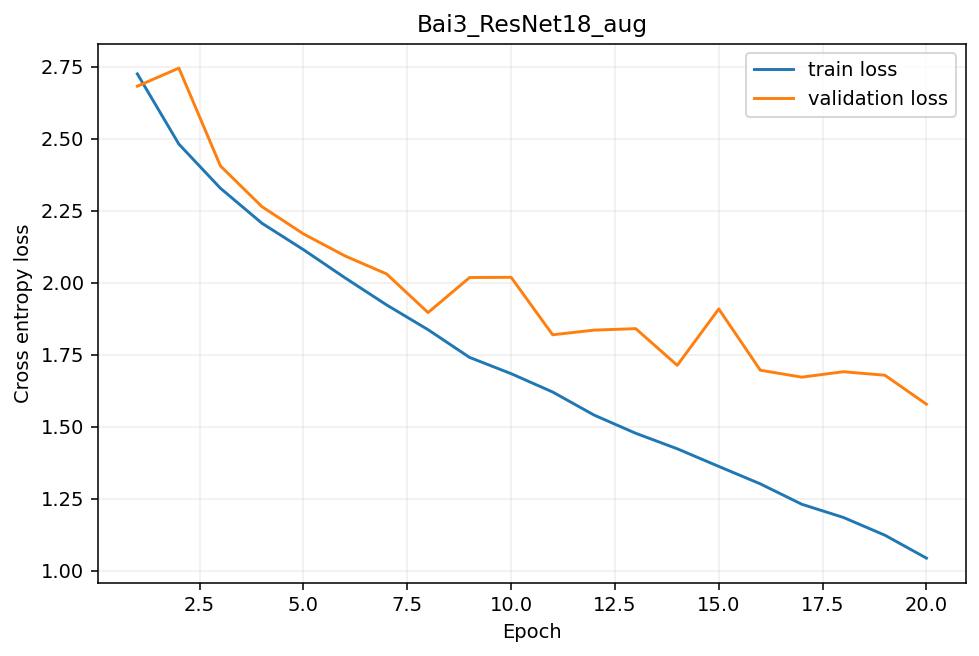

### Hình loss đã lưu — `Bai3_ResNet18_noaug_loss.png`

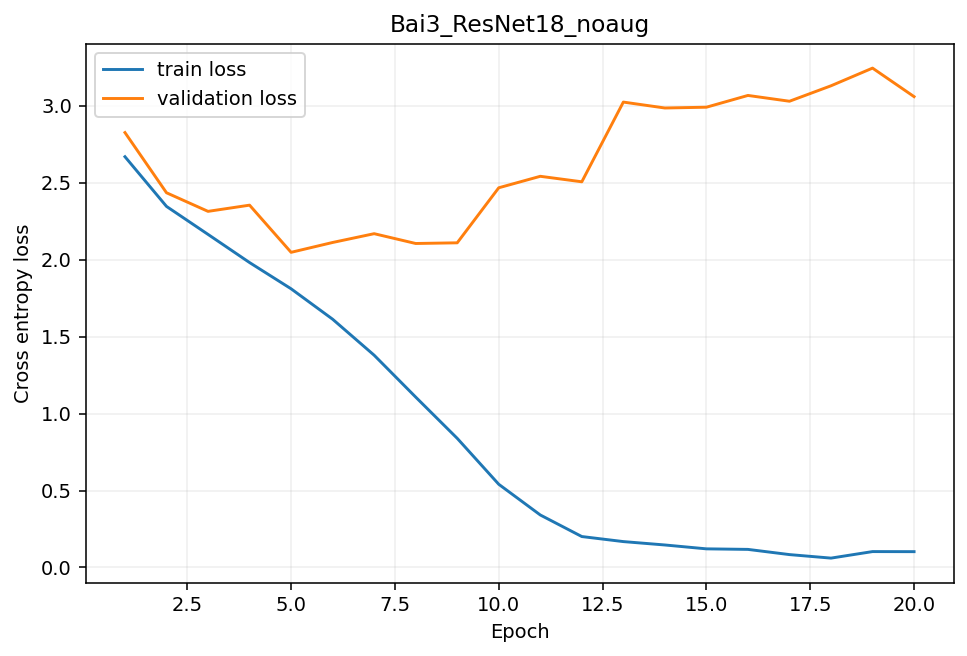

In [7]:
loss_files = sorted(OUTPUT_DIR.glob("*_loss.png"))
for path in loss_files:
    display(Markdown(f"### Hình loss đã lưu — `{path.name}`"))
    display(Image(filename=str(path)))

## 6. Kết quả đánh giá trên test

In [8]:
test_files = sorted(OUTPUT_DIR.glob("*_test.json"))
if not test_files:
    raise FileNotFoundError("Không có test JSON; cell evaluate chưa chạy thành công.")

summaries = []
for path in test_files:
    with path.open(encoding="utf-8") as stream:
        payload = json.load(stream)
    row = payload["summary"].copy()
    row["result_file"] = path.name
    summaries.append(row)

summary_frame = pd.DataFrame(summaries)
preferred = [
    "model", "best_val_epoch", "best_val_f1", "test_loss",
    "accuracy", "precision_macro", "recall_macro", "f1_macro",
    "params", "trainable_params", "seconds_per_epoch", "result_file",
]
shown = [column for column in preferred if column in summary_frame.columns]
display(summary_frame[shown].round(4))

winner = summary_frame.loc[summary_frame["f1_macro"].astype(float).idxmax()]
display(Markdown(
    f"**Mô hình tốt nhất trên test:** `{winner['model']}` — "
    f"accuracy = **{float(winner['accuracy']):.4f}**, "
    f"precision-macro = **{float(winner['precision_macro']):.4f}**, "
    f"recall-macro = **{float(winner['recall_macro']):.4f}**, "
    f"macro-F1 = **{float(winner['f1_macro']):.4f}**."
))

,model,best_val_epoch,best_val_f1,test_loss,accuracy,precision_macro,recall_macro,f1_macro,params,result_file
0,Bai3_ResNet18_aug,20,0.5236,1.7543,0.5049,0.5152,0.4986,0.4923,11187285,Bai3_ResNet18_aug_test.json
1,Bai3_ResNet18_noaug,20,0.4959,3.4970,0.4244,0.4255,0.4095,0.4090,11187285,Bai3_ResNet18_noaug_test.json


**Mô hình tốt nhất trên test:** `Bai3_ResNet18_aug` — accuracy = **0.5049**, precision-macro = **0.5152**, recall-macro = **0.4986**, macro-F1 = **0.4923**.

## 7. Kết quả từng lớp

In [9]:
per_class_files = sorted(OUTPUT_DIR.glob("*_per_class.csv"))
for path in per_class_files:
    frame = pd.read_csv(path).sort_values("f1", ascending=False)
    display(Markdown(f"### Precision/Recall/F1 từng lớp — `{path.stem.removesuffix('_per_class')}`"))
    display(frame.round(4))

### Precision/Recall/F1 từng lớp — `Bai3_ResNet18_aug`

,class,precision,recall,f1,support
13,canh-khoai-mo,0.8764,0.7879,0.8298,198
9,bo-la-lot,0.6412,0.7882,0.7071,458
12,canh-kho-qua,0.6488,0.6690,0.6587,290
19,tau-hu,0.6264,0.5369,0.5782,203
16,ha-cao,0.6019,0.5417,0.5702,480
3,banh-tet,0.7026,0.4478,0.5470,364
1,banh-hoi,0.7866,0.4069,0.5364,607
2,banh-mi-chao,0.3535,0.7889,0.4882,289
6,banh-uot,0.4901,0.4839,0.4870,560
5,banh-u,0.4573,0.5170,0.4853,176


### Precision/Recall/F1 từng lớp — `Bai3_ResNet18_noaug`

,class,precision,recall,f1,support
13,canh-khoai-mo,0.7337,0.7374,0.7355,198
9,bo-la-lot,0.6084,0.6310,0.6195,458
19,tau-hu,0.5266,0.5369,0.5317,203
1,banh-hoi,0.4228,0.5552,0.4801,607
8,bo-kho,0.5641,0.3905,0.4615,338
2,banh-mi-chao,0.3738,0.5536,0.4463,289
16,ha-cao,0.4667,0.4229,0.4437,480
12,canh-kho-qua,0.4936,0.4000,0.4419,290
3,banh-tet,0.5841,0.3434,0.4325,364
18,pha-lau,0.3816,0.4489,0.4125,352


## 8. Confusion matrix

### Confusion matrix — `Bai3_ResNet18_aug`

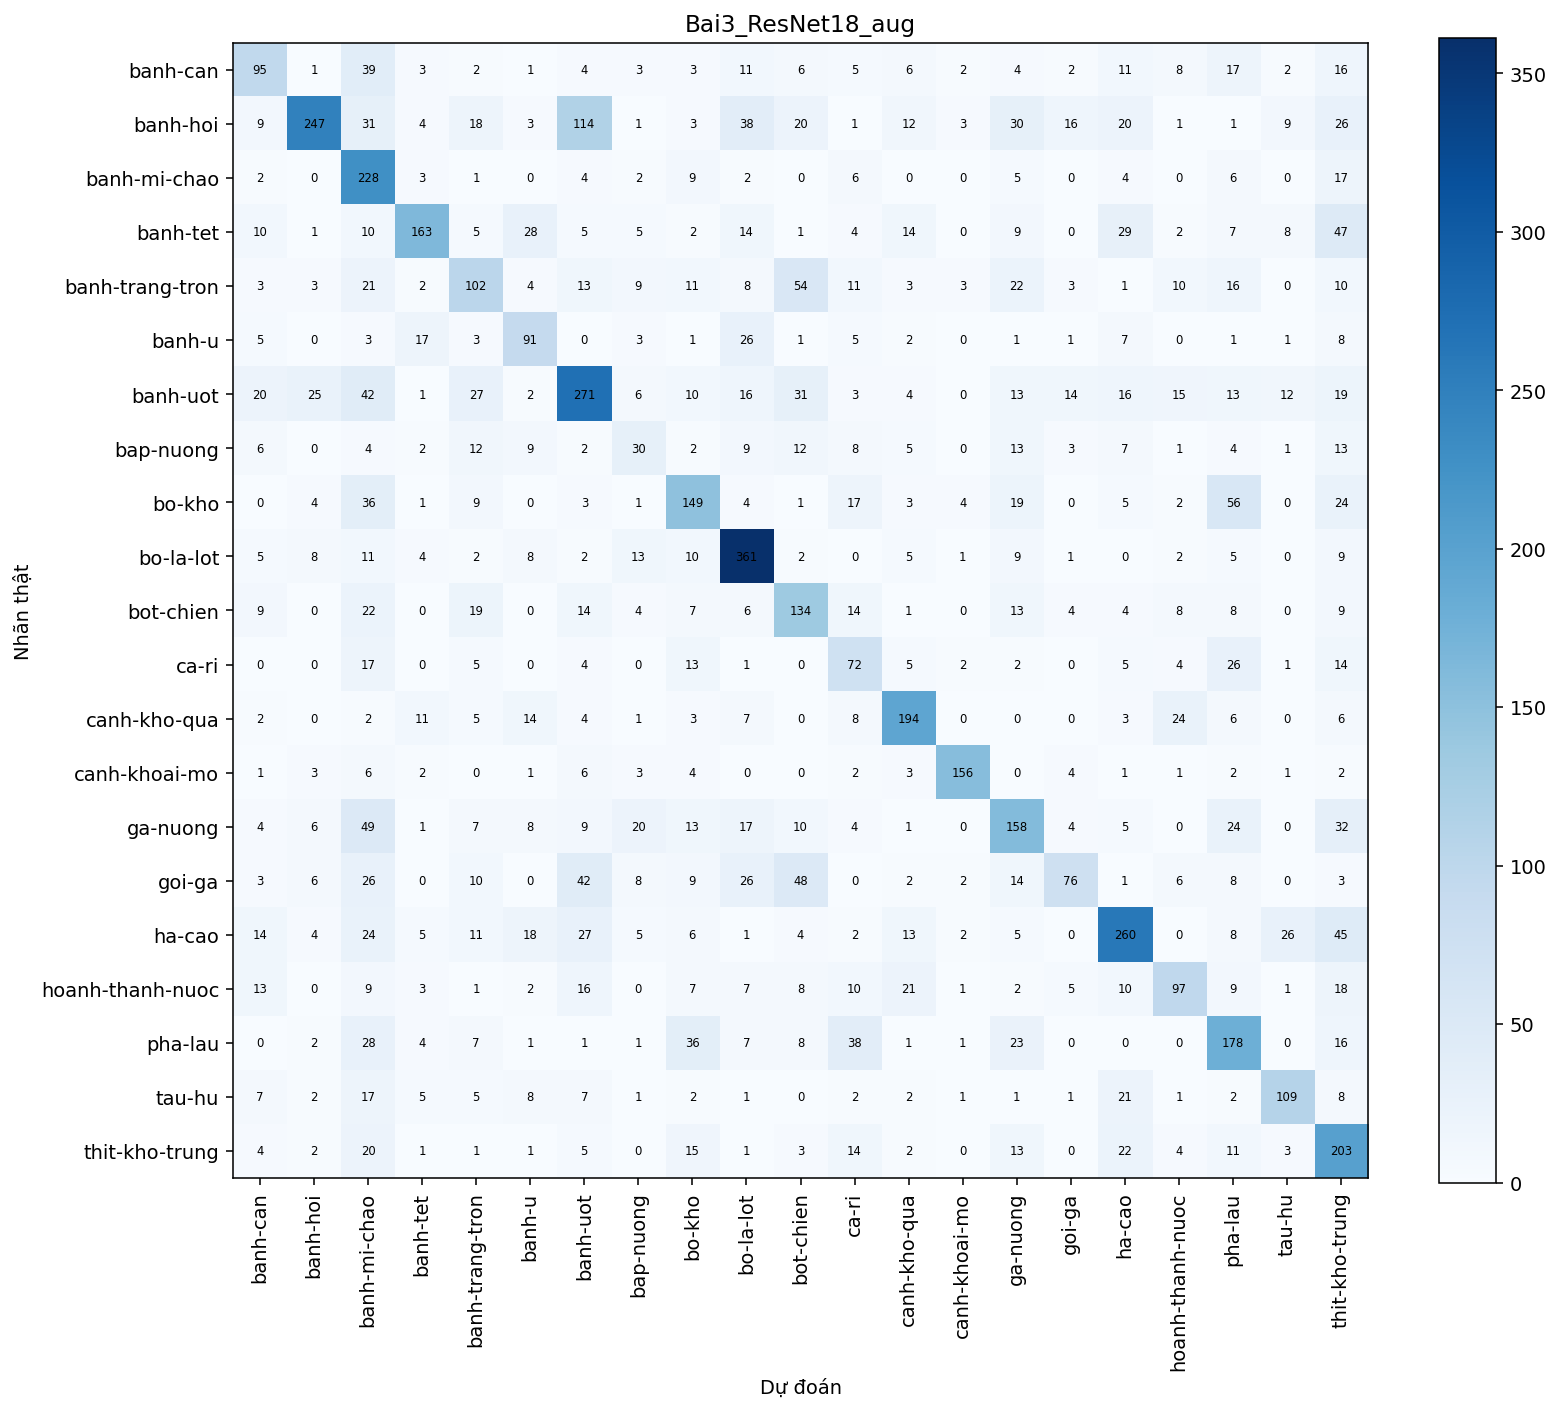

### Confusion matrix — `Bai3_ResNet18_noaug`

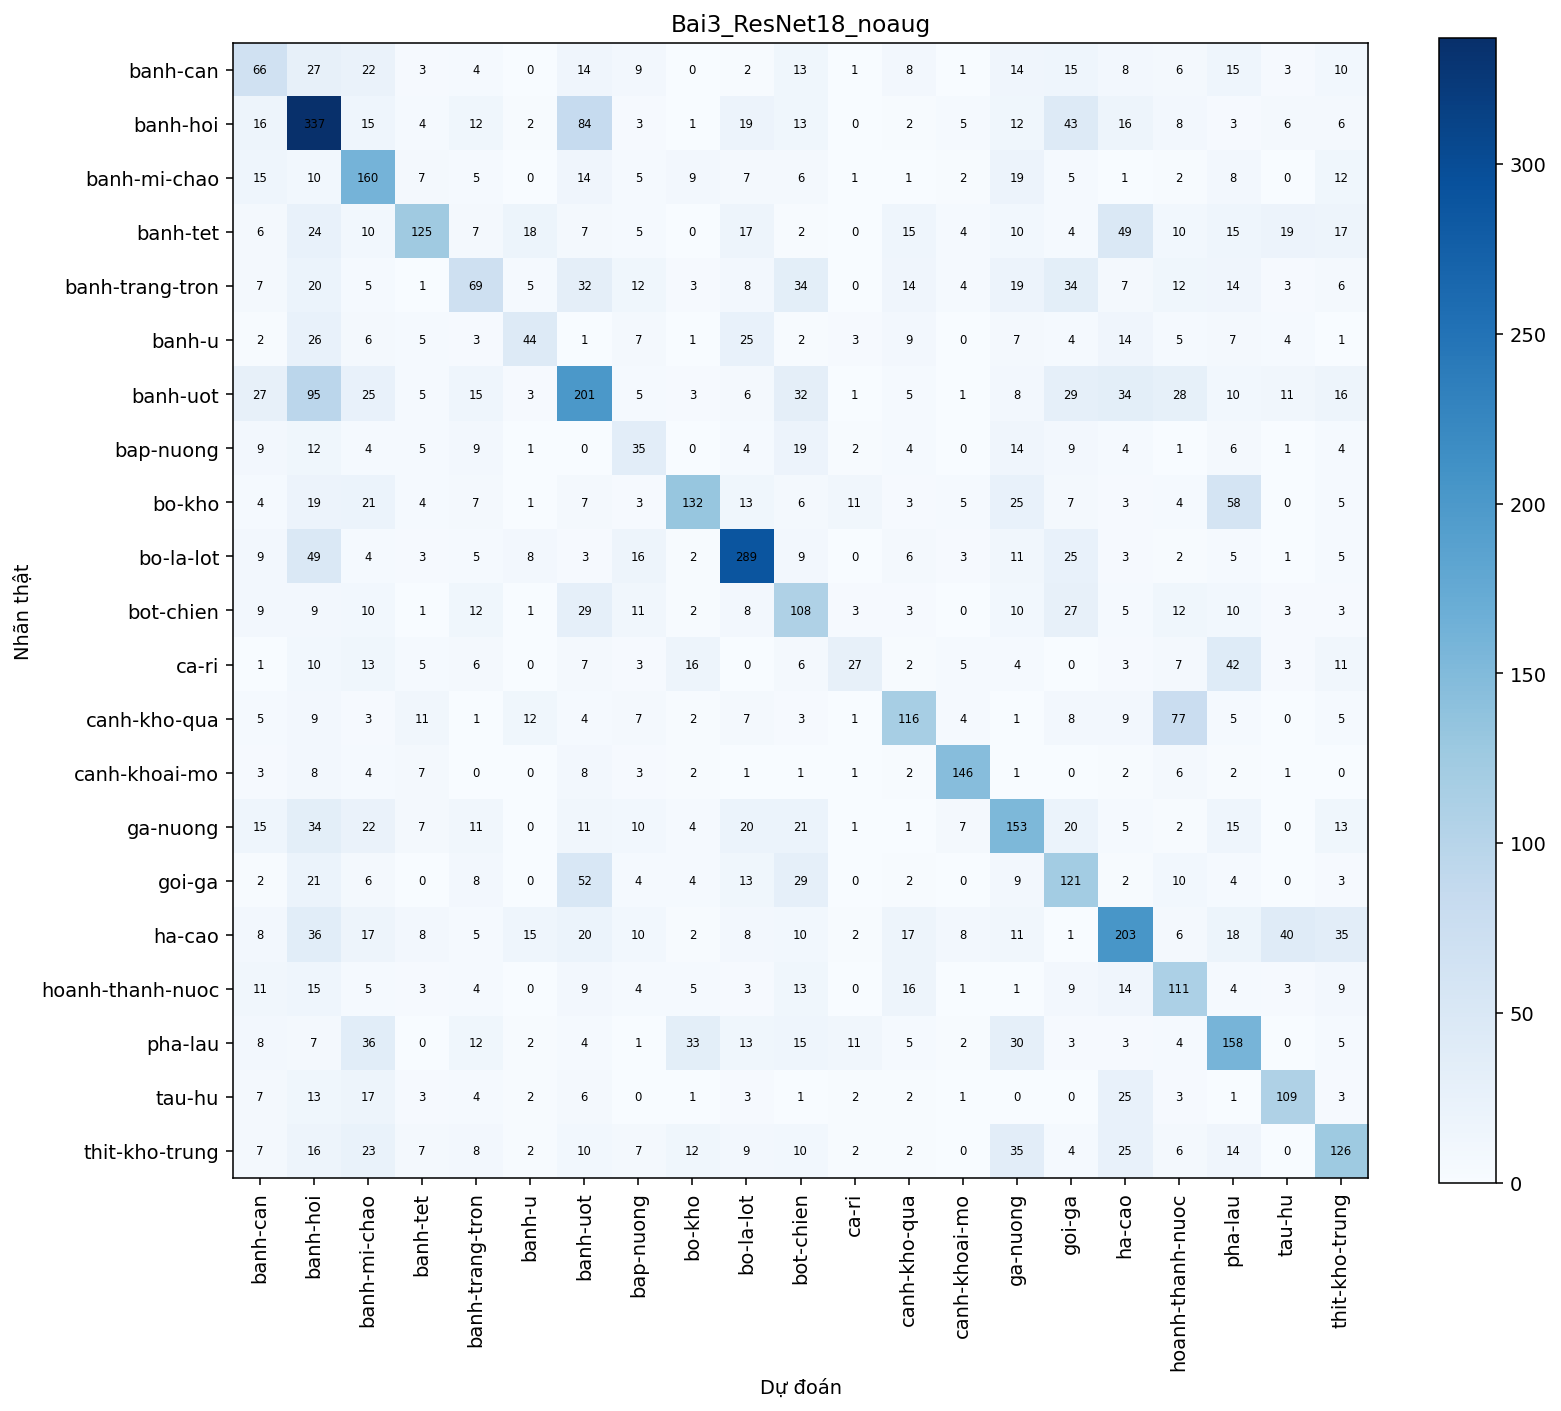

In [10]:
matrix_files = sorted(OUTPUT_DIR.glob("*_confusion_matrix.png"))
for path in matrix_files:
    display(Markdown(f"### Confusion matrix — `{path.stem.removesuffix('_confusion_matrix')}`"))
    display(Image(filename=str(path)))

## 9. Danh sách artifact

In [11]:
rows = [
    {"file": path.name, "size_MB": round(path.stat().st_size / 1024**2, 3)}
    for path in sorted(OUTPUT_DIR.glob("*")) if path.is_file()
]
display(pd.DataFrame(rows))
print("Tất cả artifact được lưu tại:", OUTPUT_DIR)

,file,size_MB
0,Bai3_ResNet18_aug_best.pt,42.750
1,Bai3_ResNet18_aug_confusion_matrix.png,0.172
2,Bai3_ResNet18_aug_history.csv,0.002
3,Bai3_ResNet18_aug_loss.png,0.060
4,Bai3_ResNet18_aug_per_class.csv,0.001
5,Bai3_ResNet18_aug_test.json,0.008
6,Bai3_ResNet18_noaug_best.pt,42.750
7,Bai3_ResNet18_noaug_confusion_matrix.png,0.176
8,Bai3_ResNet18_noaug_history.csv,0.002
9,Bai3_ResNet18_noaug_loss.png,0.052


Tất cả artifact được lưu tại: /kaggle/working/lab2_bai3_outputs


## Kết luận

- Checkpoint được lựa chọn bằng **macro-F1 trên validation**, không dùng test để chọn epoch.
- Các chỉ số test gồm accuracy, precision-macro, recall-macro và macro-F1.